# Superstore Sales & Profitability Analysis
### Python Data Preparation, Exploratory Analysis & Financial KPI Validation | 2014–2017

**Portfolio case study** · Python · Pandas · NumPy · Matplotlib · MySQL / Power BI reconciliation

**Business objective.** Assess retail sales performance and profitability across time, geography, product categories, customer segments, and discount levels. This notebook documents the reproducible Python analysis supporting the executive dashboard.

**Scope.** Sample Superstore data, 9,994 **order-line** records (not 9,994 distinct orders). Financial values are reported in USD. Conclusions are descriptive and do not establish causation.

**Notebook guide:** Load → Audit → Prepare → Validate → Analyze → Summarize. Run cells from top to bottom. Store `Sample - Superstore.csv` in the same folder as this notebook. For convenience, the previously prepared `Sample-Superstore-Cleaned.csv` is also accepted as a fallback.

## 1. Environment & data ingestion

**Reproducibility:** This notebook uses relative file paths and does not require a database connection. It prioritizes the original `Sample - Superstore.csv`; if that file is unavailable, it can read the prepared CSV. The original CSV uses a legacy text encoding (`latin1`), while the prepared export uses UTF-8.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)

SOURCE_CANDIDATES = [
    (Path("Sample - Superstore.csv"), "latin1"),
    (Path("Sample-Superstore-Cleaned.csv"), "utf-8-sig"),
    (Path("data/Sample - Superstore.csv"), "latin1"),
    (Path("data/Sample-Superstore-Cleaned.csv"), "utf-8-sig"),
]

available = [(path, encoding) for path, encoding in SOURCE_CANDIDATES if path.is_file()]
if not available:
    raise FileNotFoundError(
        "Dataset not found. Put 'Sample - Superstore.csv' beside this notebook "
        "or update SOURCE_CANDIDATES to its relative path."
    )

source_path, source_encoding = available[0]
raw_df = pd.read_csv(source_path, encoding=source_encoding, dtype={"Postal Code": "string"})
print(f"Source: {source_path} | Encoding: {source_encoding}")
print(f"Imported: {len(raw_df):,} rows × {raw_df.shape[1]} columns")
display(raw_df.head(3))

Source: Sample-Superstore-Cleaned.csv | Encoding: utf-8-sig
Imported: 9,994 rows × 26 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Days,Profit Margin,Order Year,Order Month,Order Quarter
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.0000,41.9136,3,0.1600,2016,November,4
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.0000,219.5820,3,0.3000,2016,November,4
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.0000,6.8714,4,0.4700,2016,June,2


## 2. Initial data quality audit

Check the source's record structure, missing financial values, duplicates, date fields, and discount range **before** interpreting results. An `Order ID` can appear on multiple rows because an order can contain several products.

In [2]:
REQUIRED_COLUMNS = {
    "Row ID", "Order ID", "Customer ID", "Product ID", "Product Name",
    "Order Date", "Ship Date", "Region", "Category", "Sub-Category",
    "Segment", "Sales", "Profit", "Discount", "Quantity",
}
missing_columns = sorted(REQUIRED_COLUMNS - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

source_audit = pd.DataFrame(
    {
        "Check": [
            "Source rows", "Source columns", "Duplicate complete rows",
            "Duplicate Row IDs", "Missing Order IDs", "Missing Sales",
            "Missing Profit", "Missing Order Dates", "Missing Ship Dates",
        ],
        "Result": [
            len(raw_df), raw_df.shape[1], int(raw_df.duplicated().sum()),
            int(raw_df["Row ID"].duplicated().sum()),
            int(raw_df["Order ID"].isna().sum()),
            int(raw_df["Sales"].isna().sum()),
            int(raw_df["Profit"].isna().sum()),
            int(raw_df["Order Date"].isna().sum()),
            int(raw_df["Ship Date"].isna().sum()),
        ],
    }
)
display(source_audit)

,Check,Result
0,Source rows,9994
1,Source columns,26
2,Duplicate complete rows,0
3,Duplicate Row IDs,0
4,Missing Order IDs,0
5,Missing Sales,0
6,Missing Profit,0
7,Missing Order Dates,0
8,Missing Ship Dates,0


In [3]:
display(raw_df[["Sales", "Profit", "Discount", "Quantity"]].describe().round(2))
print("Discount values:", sorted(raw_df["Discount"].dropna().unique().tolist()))
print("Regions:", sorted(raw_df["Region"].dropna().unique().tolist()))

,Sales,Profit,Discount,Quantity
count,"9,994.0000","9,994.0000","9,994.0000","9,994.0000"
mean,229.8600,28.6600,0.1600,3.7900
std,623.2500,234.2600,0.2100,2.2300
min,0.4400,"-6,599.9800",0.0000,1.0000
25%,17.2800,1.7300,0.0000,2.0000
50%,54.4900,8.6700,0.2000,3.0000
75%,209.9400,29.3600,0.2000,5.0000
max,"22,638.4800","8,399.9800",0.8000,14.0000


Discount values: [0.0, 0.1, 0.15, 0.2, 0.3, 0.32, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8]
Regions: ['Central', 'East', 'South', 'West']


## 3. Data preparation & feature engineering

Convert dates to actual datetime values and create five analytical fields: `Shipping Days`, **row-level** `Profit Margin`, `Order Year`, `Order Month`, and `Order Quarter`.

**Important distinction:** A row-level margin is useful for inspecting transactions, but aggregate margins must always be calculated as **sum(Profit) / sum(Sales)**. Averaging row-level margins would weight a $1 transaction equally with a $1,000 transaction.

For repeatable results, derived fields are recalculated even when the prepared CSV is loaded.

In [4]:
DERIVED_COLUMNS = [
    "Shipping Days", "Profit Margin", "Order Year", "Order Month", "Order Quarter"
]
base_columns = [column for column in raw_df.columns if column not in DERIVED_COLUMNS]
clean_df = raw_df[base_columns].copy()

# Accept both the original M/D/YYYY dates and the prepared YYYY-MM-DD export.
def parse_superstore_dates(values: pd.Series) -> pd.Series:
    non_missing = values.dropna()
    if non_missing.empty:
        return pd.to_datetime(values, errors="coerce")
    sample = str(non_missing.iloc[0])
    date_format = "%Y-%m-%d" if sample[:4].isdigit() and sample[4:5] == "-" else "%m/%d/%Y"
    return pd.to_datetime(values, format=date_format, errors="coerce")

for date_column in ["Order Date", "Ship Date"]:
    clean_df[date_column] = parse_superstore_dates(clean_df[date_column])

clean_df["Shipping Days"] = (clean_df["Ship Date"] - clean_df["Order Date"]).dt.days
clean_df["Profit Margin"] = clean_df["Profit"].div(clean_df["Sales"].replace(0, np.nan))
clean_df["Order Year"] = clean_df["Order Date"].dt.year.astype("Int64")
clean_df["Order Month"] = clean_df["Order Date"].dt.month_name()
clean_df["Order Quarter"] = clean_df["Order Date"].dt.quarter.astype("Int64")

display(clean_df[[
    "Order ID", "Order Date", "Ship Date", "Shipping Days",
    "Sales", "Profit", "Profit Margin", "Order Year"
]].head(5))

,Order ID,Order Date,Ship Date,Shipping Days,Sales,Profit,Profit Margin,Order Year
0,CA-2016-152156,2016-11-08,2016-11-11,3,261.9600,41.9136,0.1600,2016
1,CA-2016-152156,2016-11-08,2016-11-11,3,731.9400,219.5820,0.3000,2016
2,CA-2016-138688,2016-06-12,2016-06-16,4,14.6200,6.8714,0.4700,2016
3,US-2015-108966,2015-10-11,2015-10-18,7,957.5775,-383.0310,-0.4000,2015
4,US-2015-108966,2015-10-11,2015-10-18,7,22.3680,2.5164,0.1125,2015


In [5]:
quality_checks = pd.DataFrame(
    {
        "Check": [
            "Prepared rows", "Prepared columns", "Missing parsed dates",
            "Negative shipping intervals", "Missing Sales/Profit",
            "Zero Sales rows", "Discount outside 0–1", "Duplicate Row IDs",
        ],
        "Count": [
            len(clean_df), clean_df.shape[1],
            int(clean_df[["Order Date", "Ship Date"]].isna().any(axis=1).sum()),
            int(clean_df["Shipping Days"].lt(0).sum()),
            int(clean_df[["Sales", "Profit"]].isna().any(axis=1).sum()),
            int(clean_df["Sales"].eq(0).sum()),
            int((~clean_df["Discount"].between(0, 1)).sum()),
            int(clean_df["Row ID"].duplicated().sum()),
        ],
    }
)
display(quality_checks)

assert len(clean_df) == 9_994, "Row count differs from the established Superstore reference."
assert clean_df["Order Date"].notna().all() and clean_df["Ship Date"].notna().all()
assert clean_df[["Sales", "Profit"]].notna().all().all()
assert clean_df["Row ID"].is_unique
assert clean_df["Shipping Days"].ge(0).all()
assert clean_df["Discount"].between(0, 1).all()
print("Core data-quality assertions passed.")

,Check,Count
0,Prepared rows,9994
1,Prepared columns,26
2,Missing parsed dates,0
3,Negative shipping intervals,0
4,Missing Sales/Profit,0
5,Zero Sales rows,0
6,Discount outside 0–1,0
7,Duplicate Row IDs,0


Core data-quality assertions passed.


**Optional export.** The validated dataset has 26 columns when loaded from the 21-column original source. Export is disabled by default to avoid overwriting existing files. Set the switch to `True` if you specifically need to regenerate the cleaned CSV for database import.

In [6]:
EXPORT_CLEANED_CSV = False
CLEANED_EXPORT_PATH = Path("Sample-Superstore-Cleaned.csv")

if EXPORT_CLEANED_CSV:
    clean_df.to_csv(CLEANED_EXPORT_PATH, index=False, encoding="utf-8")
    print(f"Exported {len(clean_df):,} records to {CLEANED_EXPORT_PATH}")
else:
    print("Export skipped (set EXPORT_CLEANED_CSV = True to write the CSV).")

Export skipped (set EXPORT_CLEANED_CSV = True to write the CSV).


## 4. Executive KPIs & metric definitions

**Formulas:** Total Sales = sum of line-item Sales; Total Profit = sum of line-item Profit; Overall Profit Margin = Total Profit / Total Sales; Total Orders = distinct count of `Order ID`; Average Order Value = Total Sales / Total Orders. Average Discount is the **unweighted mean of order-line discount rates**, not an order-level average.

In [7]:
total_sales = clean_df["Sales"].sum()
total_profit = clean_df["Profit"].sum()
total_orders = clean_df["Order ID"].nunique()
overall_profit_margin = total_profit / total_sales
average_order_value = total_sales / total_orders
average_discount = clean_df["Discount"].mean()
average_shipping_days = clean_df["Shipping Days"].mean()

kpi_summary = pd.DataFrame(
    [
        ("Total Sales", f"${total_sales:,.2f}"),
        ("Total Profit", f"${total_profit:,.2f}"),
        ("Overall Profit Margin", f"{overall_profit_margin:.2%}"),
        ("Unique Orders", f"{total_orders:,}"),
        ("Unique Customers", f"{clean_df['Customer ID'].nunique():,}"),
        ("Unique Product IDs", f"{clean_df['Product ID'].nunique():,}"),
        ("Average Order Value", f"${average_order_value:,.2f}"),
        ("Mean Line-Item Discount", f"{average_discount:.2%}"),
        ("Mean Shipping Days", f"{average_shipping_days:.2f}"),
    ],
    columns=["Metric", "Result"],
)
display(kpi_summary)

,Metric,Result
0,Total Sales,"$2,297,200.86"
1,Total Profit,"$286,397.02"
2,Overall Profit Margin,12.47%
3,Unique Orders,"5,009"
4,Unique Customers,793
5,Unique Product IDs,"1,862"
6,Average Order Value,$458.61
7,Mean Line-Item Discount,15.62%
8,Mean Shipping Days,3.96


### Cross-tool reconciliation

These reference totals were established from the complete 9,994-record source and independently checked in the MySQL and Power BI workflow. `np.isclose` tolerates harmless floating-point representation differences, but not material discrepancies.

In [8]:
EXPECTED = {
    "Rows": 9_994,
    "Orders": 5_009,
    "Customers": 793,
    "Product IDs": 1_862,
    "Sales": 2_297_200.8603,
    "Profit": 286_397.0217,
}
actual = {
    "Rows": len(clean_df),
    "Orders": total_orders,
    "Customers": clean_df["Customer ID"].nunique(),
    "Product IDs": clean_df["Product ID"].nunique(),
    "Sales": total_sales,
    "Profit": total_profit,
}
reconciliation = pd.DataFrame(
    [(name, EXPECTED[name], actual[name], bool(np.isclose(EXPECTED[name], actual[name], atol=0.01, rtol=0)))
     for name in EXPECTED],
    columns=["Measure", "Expected", "Actual", "Matches"],
)
display(reconciliation)
assert reconciliation["Matches"].all(), "Reconciliation failed: inspect the source before proceeding."
print("Python KPI totals reconcile with the validated Superstore reference.")

,Measure,Expected,Actual,Matches
0,Rows,"9,994.0000","9,994.0000",True
1,Orders,"5,009.0000","5,009.0000",True
2,Customers,793.0000,793.0000,True
3,Product IDs,"1,862.0000","1,862.0000",True
4,Sales,"2,297,200.8603","2,297,200.8603",True
5,Profit,"286,397.0217","286,397.0217",True


Python KPI totals reconcile with the validated Superstore reference.


## 5. Time-series performance

Compare annual revenue, profit, and **weighted profit margin**. Year-over-year growth rates are calculated from full-year aggregates, not individual transaction rows.

In [9]:
def financial_summary(frame: pd.DataFrame, dimensions: list[str]) -> pd.DataFrame:
    summary = (
        frame.groupby(dimensions, dropna=False, observed=True)
        .agg(
            Sales=("Sales", "sum"),
            Profit=("Profit", "sum"),
            Order_Lines=("Row ID", "size"),
            Unique_Orders=("Order ID", "nunique"),
        )
        .reset_index()
    )
    summary["Profit_Margin_Pct"] = (summary["Profit"] / summary["Sales"]) * 100
    return summary

yearly_performance = financial_summary(clean_df, ["Order Year"]).sort_values("Order Year")
yearly_performance["Sales_YoY_Pct"] = yearly_performance["Sales"].pct_change() * 100
yearly_performance["Profit_YoY_Pct"] = yearly_performance["Profit"].pct_change() * 100
display(yearly_performance.round(2))

,Order Year,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct,Sales_YoY_Pct,Profit_YoY_Pct
0,2014,"484,247.5000","49,543.9700",1993,969,10.2300,NaN,NaN
1,2015,"470,532.5100","61,618.6000",2102,1038,13.1000,-2.8300,24.3700
2,2016,"609,205.6000","81,795.1700",2587,1315,13.4300,29.4700,32.7400
3,2017,"733,215.2600","93,439.2700",3312,1687,12.7400,20.3600,14.2400


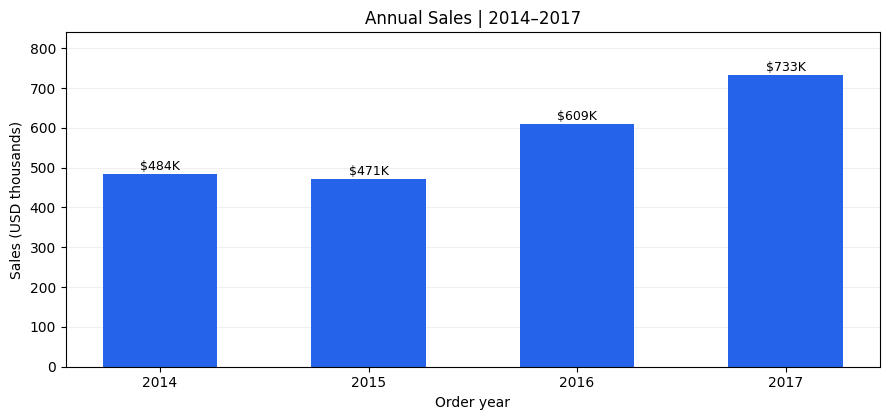

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.bar(yearly_performance["Order Year"].astype(str), yearly_performance["Sales"] / 1_000,
       color="#2563EB", width=0.55)
ax.set(title="Annual Sales | 2014–2017", ylabel="Sales (USD thousands)", xlabel="Order year")
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
for x, value in enumerate(yearly_performance["Sales"]):
    ax.text(x, value / 1_000 + 10, f"${value / 1_000:,.0f}K", ha="center", fontsize=9)
ax.set_ylim(0, 840)
plt.tight_layout()
plt.show()

**Interpretation.** Annual sales rose **20.36%** from 2016 to 2017, while profit rose **14.24%**. Profit margin declined from **13.43%** to **12.74%** (approximately **0.68 percentage points**). Higher revenue did not produce proportionate profit growth.

## 6. Regional profitability

Regional revenue rankings should be evaluated alongside total profit and profit margin. A region with higher sales can still generate less profit.

In [11]:
region_performance = (
    financial_summary(clean_df, ["Region"])
    .sort_values("Sales", ascending=False)
    .reset_index(drop=True)
)
display(region_performance.round(2))

,Region,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct
0,West,"725,457.8200","108,418.4500",3203,1611,14.9400
1,East,"678,781.2400","91,522.7800",2848,1401,13.4800
2,Central,"501,239.8900","39,706.3600",2323,1175,7.9200
3,South,"391,721.9000","46,749.4300",1620,822,11.9300


**Interpretation.** West leads in sales and profit. Central generated about **$109.5K more sales** than South but about **$7.0K less profit**; Central also has the lowest regional margin (**7.92%**). The differences warrant investigation of category mix, discounting, and costs, not an automatic conclusion about causes.

## 7. Category, subcategory & product profitability

Evaluate category-level profit margins using aggregated totals. Investigate loss-making subcategories without assuming that high revenue implies healthy profitability.

In [12]:
category_performance = (
    financial_summary(clean_df, ["Category"])
    .sort_values("Profit_Margin_Pct", ascending=False)
    .reset_index(drop=True)
)
display(category_performance.round(2))

,Category,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct
0,Technology,"836,154.0300","145,454.9500",1847,1544,17.4000
1,Office Supplies,"719,047.0300","122,490.8000",6026,3742,17.0400
2,Furniture,"741,999.8000","18,451.2700",2121,1764,2.4900


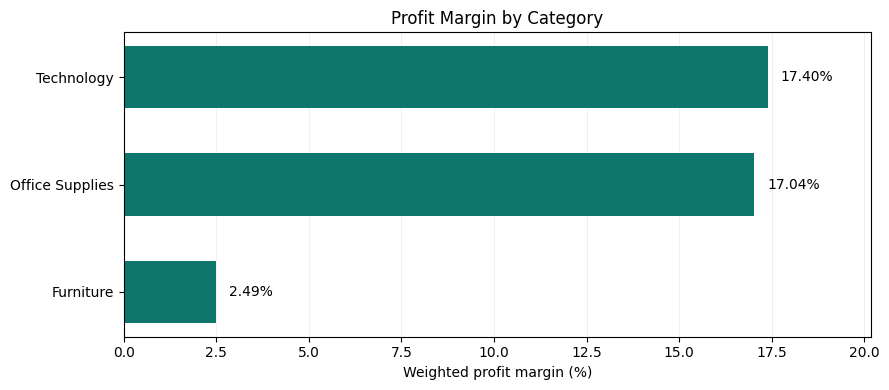

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(category_performance["Category"], category_performance["Profit_Margin_Pct"],
        color="#0F766E", height=0.58)
ax.invert_yaxis()
ax.set(title="Profit Margin by Category", xlabel="Weighted profit margin (%)")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
for y, margin in enumerate(category_performance["Profit_Margin_Pct"]):
    ax.text(margin + 0.35, y, f"{margin:.2f}%", va="center", fontsize=10)
ax.set_xlim(0, max(category_performance["Profit_Margin_Pct"]) * 1.16)
plt.tight_layout()
plt.show()

In [14]:
subcategory_performance = (
    financial_summary(clean_df, ["Category", "Sub-Category"])
    .sort_values("Profit")
)
print("Five lowest-profit subcategories:")
display(subcategory_performance.head(5).round(2))
print("Five highest-profit subcategories:")
display(subcategory_performance.tail(5).sort_values("Profit", ascending=False).round(2))

Five lowest-profit subcategories:


,Category,Sub-Category,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct
3,Furniture,Tables,"206,965.5300","-17,725.4800",319,307,-8.5600
0,Furniture,Bookcases,"114,880.0000","-3,472.5600",228,224,-3.0200
12,Office Supplies,Supplies,"46,673.5400","-1,189.1000",190,187,-2.5500
8,Office Supplies,Fasteners,"3,024.2800",949.5200,217,215,31.4000
15,Technology,Machines,"189,238.6300","3,384.7600",115,112,1.7900


Five highest-profit subcategories:


,Category,Sub-Category,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct
14,Technology,Copiers,"149,528.0300","55,617.8200",68,68,37.2000
16,Technology,Phones,"330,007.0500","44,515.7300",889,814,13.4900
13,Technology,Accessories,"167,380.3200","41,936.6400",775,718,25.0500
10,Office Supplies,Paper,"78,479.2100","34,053.5700",1370,1191,43.3900
6,Office Supplies,Binders,"203,412.7300","30,221.7600",1523,1316,14.8600


**Interpretation.** Furniture contributes approximately **$742.0K in sales** but only **$18.5K in profit** (**2.49% margin**). Tables is an especially important loss-making subcategory, with about **$17.7K negative profit**. This identifies an investigation priority, not a proven pricing or discounting cause.

In [15]:
# Product ID and Product Name are not perfectly one-to-one in this source.
# Use both fields so unrelated records are not merged under an ambiguous name.
product_profitability = (
    financial_summary(clean_df, ["Product ID", "Product Name"])
    .sort_values("Profit")
)
print("Five lowest-profit product ID/name combinations:")
display(product_profitability.head(5).round(2))
print("Five highest-profit product ID/name combinations:")
display(product_profitability.tail(5).sort_values("Profit", ascending=False).round(2))
print("Distinct Product IDs:", clean_df["Product ID"].nunique())
print("Distinct Product Names:", clean_df["Product Name"].nunique())
print("Distinct ID/name combinations:", len(product_profitability))

Five lowest-profit product ID/name combinations:


,Product ID,Product Name,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,"11,099.9600","-8,879.9700",3,3,-80.0000
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,"16,829.9000","-4,589.9700",4,4,-27.2700
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,"7,999.9800","-3,839.9900",1,1,-48.0000
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,"9,917.6400","-2,876.1200",5,5,-29.0000
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,"9,544.7200","-1,934.4000",7,7,-20.2700


Five highest-profit product ID/name combinations:


,Product ID,Product Name,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,"61,599.8200","25,199.9300",5,5,40.9100
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,"27,453.3800","7,753.0400",10,10,28.2400
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,"18,839.6900","6,983.8800",8,8,37.0700
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,"11,619.8300","4,570.9300",4,4,39.3400
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,"18,374.9000","4,094.9800",3,3,22.2900


Distinct Product IDs: 1862
Distinct Product Names: 1850
Distinct ID/name combinations: 1894


## 8. Discount patterns & profitability

To mirror the Power BI dashboard, group **order lines** by their recorded discount rate. These group names are display labels, not assumptions that discounts are integer percentages. Discount groups do **not** equal unique orders.

- `0% (None)` = discount equals 0
- `1–10%` = discount above 0 up to 10%
- `11–20%` = discount above 10% up to 20%
- `21–30%` = discount above 20% up to 30%
- `Over 30%` = discount above 30%

In [16]:
band_order = ["0% (None)", "1–10%", "11–20%", "21–30%", "Over 30%"]
conditions = [
    clean_df["Discount"].eq(0),
    clean_df["Discount"].gt(0) & clean_df["Discount"].le(0.10),
    clean_df["Discount"].gt(0.10) & clean_df["Discount"].le(0.20),
    clean_df["Discount"].gt(0.20) & clean_df["Discount"].le(0.30),
    clean_df["Discount"].gt(0.30),
]
clean_df["Discount Band"] = pd.Categorical(
    np.select(conditions, band_order, default="Unknown"),
    categories=[*band_order, "Unknown"], ordered=True,
)
assert not clean_df["Discount Band"].eq("Unknown").any()

discount_performance = financial_summary(clean_df, ["Discount Band"])
discount_performance = discount_performance[
    discount_performance["Discount Band"] != "Unknown"
].sort_values("Discount Band")
display(discount_performance.round(2))

,Discount Band,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct
0,0% (None),"1,087,908.4700","320,987.6000",4798,2644,29.5100
1,1–10%,"54,369.3500","9,029.1800",94,89,16.6100
2,11–20%,"792,152.8900","91,756.3000",3709,2436,11.5800
3,21–30%,"103,226.6600","-10,369.2800",227,211,-10.0500
4,Over 30%,"259,543.4900","-125,006.7800",1166,888,-48.1600


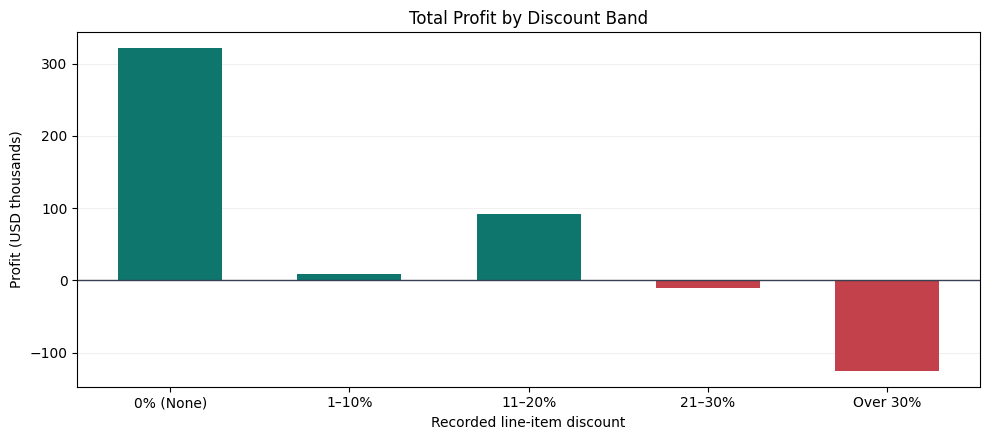

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bar_colors = np.where(discount_performance["Profit"] >= 0, "#0F766E", "#C2414B")
ax.bar(discount_performance["Discount Band"].astype(str),
       discount_performance["Profit"] / 1_000, color=bar_colors, width=0.58)
ax.axhline(0, color="#374151", linewidth=1)
ax.set(title="Total Profit by Discount Band", ylabel="Profit (USD thousands)", xlabel="Recorded line-item discount")
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [18]:
no_discount_profit = clean_df.loc[clean_df["Discount"].eq(0), "Profit"].sum()
discounted_profit = clean_df.loc[clean_df["Discount"].gt(0), "Profit"].sum()
print(f"Profit on non-discounted order lines: ${no_discount_profit:,.2f}")
print(f"Profit on discounted order lines:     ${discounted_profit:,.2f}")
print(f"Combined profit:                    ${no_discount_profit + discounted_profit:,.2f}")
assert np.isclose(no_discount_profit + discounted_profit, total_profit, atol=0.01)

Profit on non-discounted order lines: $320,987.60
Profit on discounted order lines:     $-34,590.58
Combined profit:                    $286,397.02


**Interpretation.** Non-discounted lines generated approximately **$321.0K profit** at a **29.51% margin**, while *all* discounted lines combined generated approximately **$34.6K in net losses**. The `Over 30%` band is unprofitable in aggregate. This is an **association**, not evidence that discounts themselves caused the losses: product mix and other factors could also explain the pattern.

## 9. Customer segments & fulfillment context

Segment comparisons provide business context. Mean shipping days is calculated over **order lines**, so orders with multiple lines may receive greater weight; it is not an order-weighted shipping service-level metric.

In [19]:
segment_performance = (
    financial_summary(clean_df, ["Segment"])
    .sort_values("Sales", ascending=False)
)
display(segment_performance.round(2))

shipping_summary = (
    clean_df.groupby("Ship Mode", dropna=False)
    .agg(Order_Lines=("Row ID", "size"), Average_Shipping_Days=("Shipping Days", "mean"))
    .reset_index()
    .sort_values("Order_Lines", ascending=False)
)
display(shipping_summary.round(2))

,Segment,Sales,Profit,Order_Lines,Unique_Orders,Profit_Margin_Pct
0,Consumer,"1,161,401.3400","134,119.2100",5191,2586,11.5500
1,Corporate,"706,146.3700","91,979.1300",3020,1514,13.0300
2,Home Office,"429,653.1500","60,298.6800",1783,909,14.0300


,Ship Mode,Order_Lines,Average_Shipping_Days
3,Standard Class,5968,5.0100
2,Second Class,1945,3.2400
0,First Class,1538,2.1800
1,Same Day,543,0.0400


## 10. Final data integrity checks

Before a dashboard or external SQL report is trusted, validate both **record completeness** and **aggregated values**. An import process can report success even if records were omitted. In this project, a MySQL Workbench import wizard produced a 9,694-row table (300 short); the corrected `LOAD DATA LOCAL INFILE` workflow reconciled all **9,994 records** to the Python totals. The underlying parser defect was not established definitively; affected product-name fields contained embedded quotation marks.

In [20]:
assert len(clean_df) == 9_994
assert clean_df["Order ID"].nunique() == 5_009
assert clean_df["Customer ID"].nunique() == 793
assert clean_df["Product ID"].nunique() == 1_862
assert clean_df["Order Year"].min() == 2014 and clean_df["Order Year"].max() == 2017
assert np.isclose(clean_df["Sales"].sum(), 2_297_200.8603, atol=0.01)
assert np.isclose(clean_df["Profit"].sum(), 286_397.0217, atol=0.01)
assert np.isclose(yearly_performance["Sales"].sum(), total_sales, atol=0.01)
assert np.isclose(region_performance["Profit"].sum(), total_profit, atol=0.01)
assert np.isclose(category_performance["Sales"].sum(), total_sales, atol=0.01)
assert np.isclose(discount_performance["Profit"].sum(), total_profit, atol=0.01)
print("PASS — 9,994 rows, 5,009 orders, financial totals and grouped aggregations reconcile.")

PASS — 9,994 rows, 5,009 orders, financial totals and grouped aggregations reconcile.


## 11. Executive conclusions & next steps

| Finding | Evidence | Recommended follow-up |
|---|---|---|
| Furniture has weak profitability | ~$742K sales, ~$18.5K profit, **2.49%** margin; Tables loses ~$17.7K | Review Tables pricing, discounts, and cost drivers at product level |
| Discounted lines underperform | No-discount profit **~$321K**; discounted lines combined **~-$34.6K** | Compare like-for-like products, segments, and discount practices |
| Regional revenue and profit rankings diverge | Central's sales exceed South's, but Central earns less profit | Break down both regions by category, product, and discount |
| Margin softened as sales grew | Sales +**20.36%** in 2017; profit +**14.24%**; margin fell ~**0.68 pp** | Investigate changes in product mix and pricing over time |

**Limits:** This historical practice dataset supports descriptive analysis, not causal claims, future forecasts, or a conclusion that any particular business intervention will work. Product identifiers and names are not perfectly one-to-one. Profit and margin measures here are based on the supplied fields, not a fully modeled income statement.

**Portfolio handoff:** The reconciled dataset and DAX measures underpin the accompanying Power BI executive dashboard. Interactive slicers and tooltips allow the same questions to be investigated across years and regions; see the project README and `docs/executive_insights.md` for the management-oriented narrative.